In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn pymongo python-dotenv streamlit joblib

  Using cached dnspython-2.9.0-py3-none-any.whl.metadata (5.7 kB)
   ---------------------------------------- 0.0/829.7 kB ? eta -:--:--
   ---------------------------------------- 829.7/829.7 kB 12.1 MB/s  0:00:00
Using cached dnspython-2.9.0-py3-none-any.whl (354 kB)

   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   ---------------------------------------- 0/2 [dnspython]
   -------------------- ------------------- 1/2 [pymongo]
   -------------------- ------------------- 1/2 [pymongo]
   -------------------- ------------------- 1/2 [pymongo]
   ---------------------------------------- 2/2 [pymongo]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

df.to_csv("energy_consumption.csv", index=False)

print("TXT converted to CSV successfully!")
print(df.head())
print("Dataset shape:", df.shape)

TXT converted to CSV successfully!
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  
Dataset shape: (2075259, 9)


In [3]:
import numpy as np

df.columns = df.columns.str.strip()

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

df = df.drop(columns=["Date", "Time"])
df = df.dropna(subset=["Datetime"] + columns)
df = df.drop_duplicates()
df = df.sort_values("Datetime").reset_index(drop=True)

df.to_csv("energy_cleaned.csv", index=False)

print("Data cleaned successfully!")
print("Rows:", len(df))
print(df.head())

Data cleaned successfully!
Rows: 2049280
   Global_active_power  Global_reactive_power  Voltage  Global_intensity  \
0                4.216                  0.418   234.84              18.4   
1                5.360                  0.436   233.63              23.0   
2                5.374                  0.498   233.29              23.0   
3                5.388                  0.502   233.74              23.0   
4                3.666                  0.528   235.68              15.8   

   Sub_metering_1  Sub_metering_2  Sub_metering_3            Datetime  
0             0.0             1.0            17.0 2006-12-16 17:24:00  
1             0.0             1.0            16.0 2006-12-16 17:25:00  
2             0.0             2.0            17.0 2006-12-16 17:26:00  
3             0.0             1.0            17.0 2006-12-16 17:27:00  
4             0.0             1.0            17.0 2006-12-16 17:28:00  


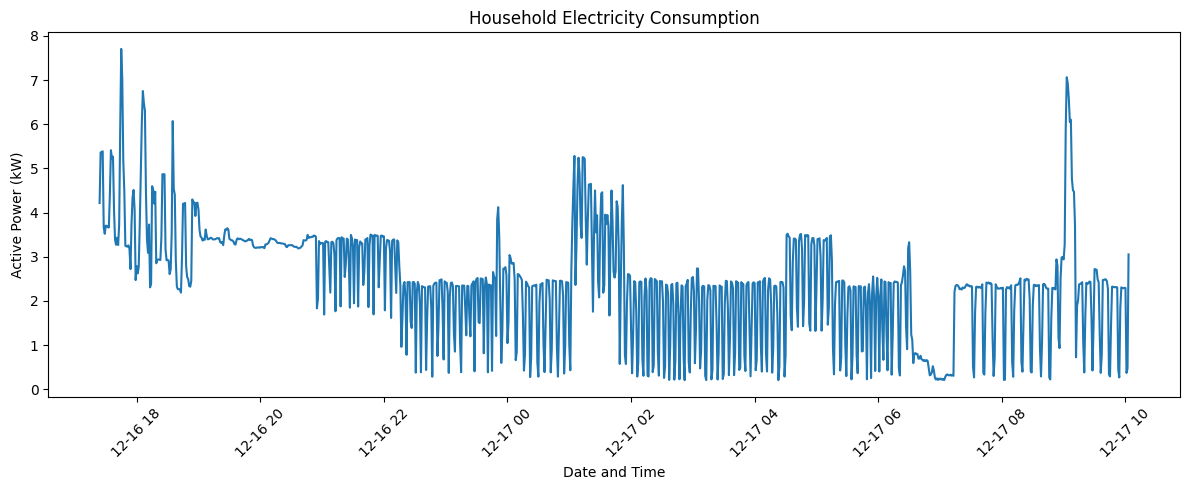

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
plt.plot(
    df["Datetime"].iloc[:1000],
    df["Global_active_power"].iloc[:1000]
)
plt.title("Household Electricity Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Active Power (kW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

       Global_active_power  Global_reactive_power       Voltage  \
count         2.049280e+06           2.049280e+06  2.049280e+06   
mean          1.091615e+00           1.237145e-01  2.408399e+02   
std           1.057294e+00           1.127220e-01  3.239987e+00   
min           7.600000e-02           0.000000e+00  2.232000e+02   
25%           3.080000e-01           4.800000e-02  2.389900e+02   
50%           6.020000e-01           1.000000e-01  2.410100e+02   
75%           1.528000e+00           1.940000e-01  2.428900e+02   
max           1.112200e+01           1.390000e+00  2.541500e+02   

       Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
count      2.049280e+06    2.049280e+06    2.049280e+06    2.049280e+06  
mean       4.627759e+00    1.121923e+00    1.298520e+00    6.458447e+00  
std        4.444396e+00    6.153031e+00    5.822026e+00    8.437154e+00  
min        2.000000e-01    0.000000e+00    0.000000e+00    0.000000e+00  
25%        1.400000e+00   

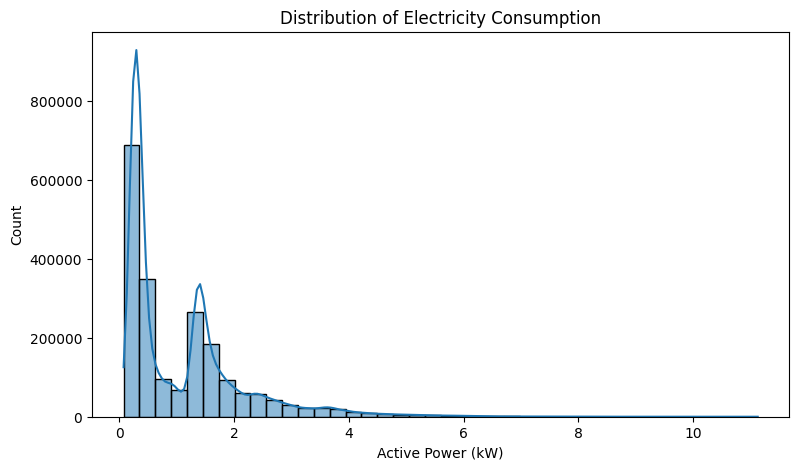

In [5]:
print(df[columns].describe())

plt.figure(figsize=(9, 5))
sns.histplot(df["Global_active_power"], bins=40, kde=True)
plt.title("Distribution of Electricity Consumption")
plt.xlabel("Active Power (kW)")
plt.show()

In [6]:
from sklearn.ensemble import IsolationForest

sample_size = min(100000, len(df))

model_df = df.sample(
    n=sample_size,
    random_state=42
).copy()

detector = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

detector.fit(model_df[columns])

model_df["is_anomaly"] = (
    detector.predict(model_df[columns]) == -1
).astype(int)

print(model_df["is_anomaly"].value_counts())

is_anomaly
0    98000
1     2000
Name: count, dtype: int64


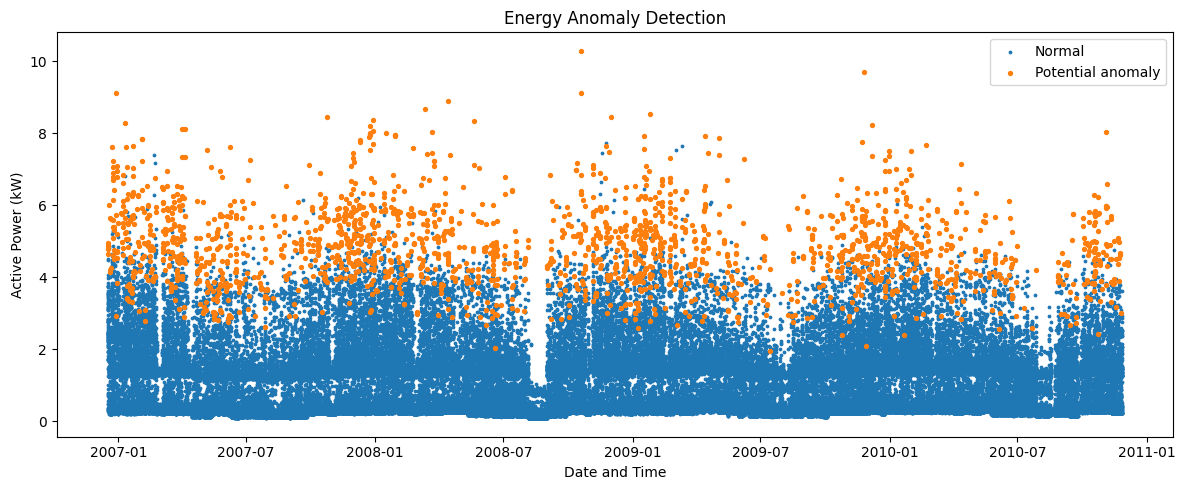

In [7]:
normal = model_df[model_df["is_anomaly"] == 0]
anomalies = model_df[model_df["is_anomaly"] == 1]

plt.figure(figsize=(12, 5))
plt.scatter(
    normal["Datetime"],
    normal["Global_active_power"],
    s=3,
    label="Normal"
)
plt.scatter(
    anomalies["Datetime"],
    anomalies["Global_active_power"],
    s=8,
    label="Potential anomaly"
)

plt.title("Energy Anomaly Detection")
plt.xlabel("Date and Time")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X = model_df.drop(
    columns=["Global_active_power", "Datetime", "is_anomaly"]
)[columns[1:]]

y = model_df["Global_active_power"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

regressor.fit(X_train, y_train)

print("Regression model trained successfully!")

Regression model trained successfully!


In [10]:
import joblib

joblib.dump(detector, "anomaly_model.pkl")
joblib.dump(regressor, "energy_model.pkl")
joblib.dump(columns, "anomaly_features.pkl")
joblib.dump(list(X.columns), "energy_features.pkl")

model_df.to_csv("energy_with_anomalies.csv", index=False)

print("Models saved successfully!")
print("Anomaly results saved to CSV!")

Models saved successfully!
Anomaly results saved to CSV!


In [11]:
import os

print(os.listdir())

['anomaly_features.pkl', 'anomaly_model.pkl', 'energy_cleaned.csv', 'energy_consumption.csv', 'energy_features.pkl', 'energy_model.pkl', 'energy_with_anomalies.csv', 'household_power_consumption.txt', 'smartenergy.ipynb']


In [14]:
sample = model_df[columns].iloc[[0]]

result = detector.predict(sample[columns])[0]

if result == -1:
    print("Potential energy anomaly detected!")
else:
    print("Energy consumption appears normal.")

regression_sample = sample[X.columns]

prediction = regressor.predict(regression_sample)[0]

print("Predicted active power:", round(prediction, 3), "kW")

Energy consumption appears normal.
Predicted active power: 1.518 kW


In [16]:
import os
import pandas as pd
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()

uri = os.getenv("MONGODB_URI")

if uri:
    client = MongoClient(uri, serverSelectionTimeoutMS=5000)
    client.admin.command("ping")

    db = client["smart_energy_db"]

    records = model_df.tail(1000).copy()
    records["Datetime"] = records["Datetime"].astype(str)
    records = records.astype(object).where(pd.notna(records), None)

    db.readings.insert_many(records.to_dict("records"))

    db.metrics.insert_one({
        "model": "IsolationForest",
        "rows_analyzed": int(len(model_df)),
        "anomalies_detected": int(model_df["is_anomaly"].sum())
    })

    print("Data saved to MongoDB Atlas!")
    client.close()
else:
    print("MONGODB_URI not found. Check your .env file.")

Data saved to MongoDB Atlas!


In [18]:
anomaly_samples = model_df[
    model_df["is_anomaly"] == 1
]

print(anomaly_samples[columns].head(5).to_string(index=False))

 Global_active_power  Global_reactive_power  Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3
               4.762                   0.55   235.53              20.4             0.0            30.0            18.0
               6.028                   0.50   232.79              26.0            43.0             1.0            17.0
               3.928                   0.44   239.06              17.2            25.0             1.0            30.0
               3.868                   0.32   236.69              16.4            38.0             0.0             0.0
               4.040                   0.32   234.22              17.2             0.0            35.0             0.0


Proxy-Based Anomaly Detection Evaluation
----------------------------------------
Accuracy: 0.9949
Precision: 0.8811
Recall: 0.8726
F1 Score: 0.8768


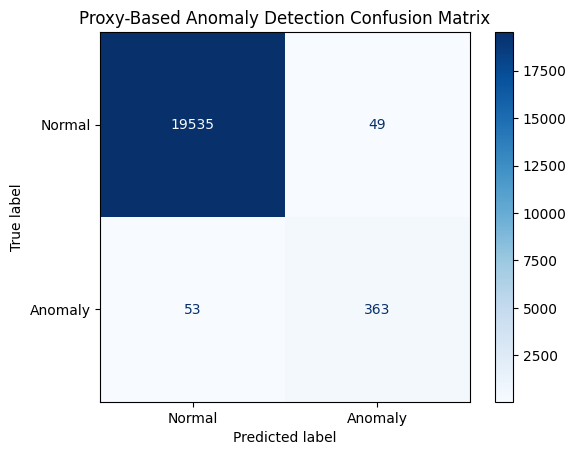


Classification Report
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     19584
     Anomaly       0.88      0.87      0.88       416

    accuracy                           0.99     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.99      0.99      0.99     20000



In [23]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import matplotlib.pyplot as plt

X = model_df[columns]

X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

reference_model = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=21,
    n_jobs=-1
)
reference_model.fit(X_train)

y_true = (reference_model.predict(X_test) == -1).astype(int)
y_pred = (detector.predict(X_test) == -1).astype(int)

print("Proxy-Based Anomaly Detection Evaluation")
print("----------------------------------------")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

cm = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)
display.plot(cmap="Blues", values_format="d")
plt.title("Proxy-Based Anomaly Detection Confusion Matrix")
plt.show()

print("\nClassification Report")
print(classification_report(
    y_true, y_pred,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report

X = model_df[columns]

X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

detector_eval = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

detector_eval.fit(X_train)

y_pred = (detector_eval.predict(X_test) == -1).astype(int)

print("Anomaly Detection Results")
print("-------------------------")
print("Test readings:", len(X_test))
print("Potential anomalies detected:", y_pred.sum())
print("Potential anomaly percentage:", round(y_pred.mean() * 100, 2), "%")

Anomaly Detection Results
-------------------------
Test readings: 20000
Potential anomalies detected: 415
Potential anomaly percentage: 2.08 %
